In [1]:

import pdfplumber
import re
import os
import pandas as pd

pdf_dir = r'C:\Users\Chilli\MachineLearning'
pdfs = [f for f in os.listdir(pdf_dir) if f.endswith('.pdf')]
print(f'Found {len(pdfs)} PDFs')

speeches = []
for i, pdf in enumerate(pdfs):
    print(f'Reading {i+1}/{len(pdfs)}: {pdf[:30]}')
    with pdfplumber.open(os.path.join(pdf_dir, pdf)) as p:
        text = ' '.join([page.extract_text() or '' for page in p.pages])
        speeches.append({'filename': pdf, 'text': text})

df = pd.DataFrame(speeches)
print(f'\nLoaded {len(df)} documents')
print(df['text'][0][:300])


#CLeaning the dataset

def cleaning_text (text):

    #Remove the page headers and page numbers
    text = re.sub(r'UNREVISED HANSARD', '')
    text= re.sub(r'NATIONAL ASSEMBLY', '')
    text = ' '.join(text.split()) 
    return text

df['cleaning_text'] = df['text'].apply(cleaning_text)
print('The text has been cleaned successfully!')
print(df['cleaning_text'][0][:300])


Found 15 PDFs
Reading 1/15: 01mfgh4vqebdhkps6o35hybjq2binz
Reading 2/15: 01mfgh4vrs3qgwmuikj5cj6rievwhc
Reading 3/15: 01mfgh4vrt7nrvqoog4nbyxvru3z4i
Reading 4/15: 01mfgh4vrt7nrvqoog4nbyxvru3z4i
Reading 5/15: 01mfgh4vtjgi2k5xduzvb37x2slyd4
Reading 6/15: 01mfgh4vtwcyucgmkhifczz3pwzhe5
Reading 7/15: 01mfgh4vu3opemllnucnayw2cpjaca
Reading 8/15: 01mfgh4vucjpey7ixnend2ac2ucbob
Reading 9/15: 01mfgh4vusyga3tyivkbd3uhd4wtvw
Reading 10/15: 01mfgh4vuz4vdknbmtunhyfbxirpfi
Reading 11/15: 01mfgh4vvopmedzdyhrjalgkmycx3e
Reading 12/15: 01mfgh4vwcjz4x27t6bjbifbjau2hg
Reading 13/15: 01mfgh4vwiswxyisrjhrgkkhi6inao
Reading 14/15: 01mfgh4vwyi6gpzwvcnrgj4g53tkbp
Reading 15/15: 01mfgh4vxmfg7rweyqlbg2kf626j6a

Loaded 15 documents
UNREVISED HANSARD
NATIONAL ASSEMBLY
WEDNESDAY, 25 MARCH 2026
Page: 1
WEDNESDAY, 25 MARCH 2026
____
PROCEEDINGS OF THE NATIONAL ASSEMBLY
____
The House met at Nieuwmeester Dome at 15:00.
The Speaker took the Chair and requested members to observe a
moment of silence for prayer or medi

TypeError: sub() missing 1 required positional argument: 'string'

In [34]:
def clean_text(text):
    text = text.replace('UNREVISED HANSARD', '')
    text = text.replace('NATIONAL ASSEMBLY', '')
    text = ' '.join(text.split())
    return text

df['clean_text'] = df['text'].apply(clean_text)
print('Text cleaned!')
print(df['clean_text'][0][:300])

Text cleaned!
WEDNESDAY, 25 MARCH 2026 Page: 1 WEDNESDAY, 25 MARCH 2026 ____ PROCEEDINGS OF THE ____ The House met at Nieuwmeester Dome at 15:00. The Speaker took the Chair and requested members to observe a moment of silence for prayer or meditation. QUESTIONS FOR ORAL REPLY CLUSTER 4 - ECONOMICS Question 260: T


In [36]:
# label the sentiment based on the keywords
def label_sentiment(text):
    text_lower = text.lower()
    
    positive_words = ['commend', 'support', 'welcome', 'progress', 'improve', 
                      'success', 'achieve', 'good', 'excellent', 'positive']
    negative_words = ['reject', 'oppose', 'fail', 'concern', 'crisis', 
                      'corrupt', 'neglect', 'unacceptable', 'delay', 'collapse']
    
    pos_score = sum(1 for w in positive_words if w in text_lower)
    neg_score = sum(1 for w in negative_words if w in text_lower)
    
    if pos_score > neg_score:
        return 'positive'
    elif neg_score > pos_score:
        return 'negative'
    else:
        return 'neutral'

df['sentiment'] = df['clean_text'].apply(label_sentiment)
print('Sentiment distribution:')
print(df['sentiment'].value_counts())

Sentiment distribution:
sentiment
negative    6
positive    5
neutral     4
Name: count, dtype: int64


In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['label'] = le.fit_transform(df['sentiment'])

print('Label mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['label'], test_size=0.2, random_state=42
)

print(f'Train: {len(X_train)} | Test: {len(X_test)}')

Label mapping: {'negative': 0, 'neutral': 1, 'positive': 2}
Train: 12 | Test: 3


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

C:\Users\Chilli\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Chilli\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenization complete!
Train input shape: torch.Size([12, 512])


In [45]:
import torch
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW

model = AutoModelForSequenceClassification.from_pretrained(
    'distilbert-base-uncased', num_labels=3
)

optimizer = AdamW(model.parameters(), lr=2e-5)
labels_train = torch.tensor(y_train.values, dtype=torch.long)  # fix here

model.train()
for epoch in range(3):
    optimizer.zero_grad()
    outputs = model(
        input_ids=train_encodings['input_ids'],
        attention_mask=train_encodings['attention_mask'],
        labels=labels_train
    )
    loss = outputs.loss
    loss.backward()
    optimizer.step()
    print(f'Epoch {epoch+1}/3 - Loss: {loss.item():.4f}')

print('Fine-tuning complete!')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 - Loss: 1.0930
Epoch 2/3 - Loss: 1.0817
Epoch 3/3 - Loss: 1.0533
Fine-tuning complete!


=== Transformer Model Evaluation ===
Accuracy : 0.3333
Precision: 0.1111
Recall   : 0.3333
F1-Score : 0.1667


ValueError: The number of FixedLocator locations (2), usually from a call to set_ticks, does not match the number of labels (3).

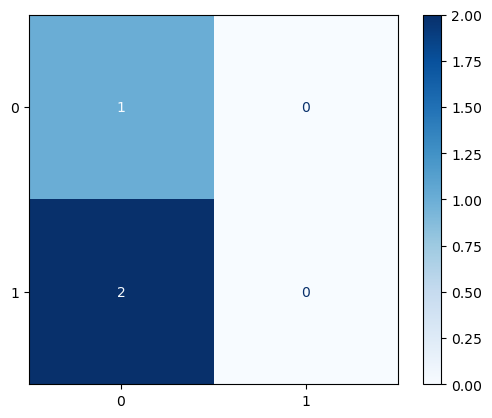

In [47]:
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()
labels_test = torch.tensor(y_test.values, dtype=torch.long)

with torch.no_grad():
    outputs = model(
        input_ids=test_encodings['input_ids'],
        attention_mask=test_encodings['attention_mask']
    )

preds = torch.argmax(outputs.logits, dim=1).numpy()
true = labels_test.numpy()

print('=== Transformer Model Evaluation ===')
print(f'Accuracy : {accuracy_score(true, preds):.4f}')
print(f'Precision: {precision_score(true, preds, average="weighted", zero_division=0):.4f}')
print(f'Recall   : {recall_score(true, preds, average="weighted", zero_division=0):.4f}')
print(f'F1-Score : {f1_score(true, preds, average="weighted", zero_division=0):.4f}')

# Confusion matrix
cm = confusion_matrix(true, preds)
disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
disp.plot(cmap='Blues')
plt.title('Sentiment Classification Confusion Matrix')
plt.tight_layout()
plt.show()

In [49]:
from sentence_transformers import SentenceTransformer
import faiss
import numpy as np

print('Generating embeddings...')
embedder = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = embedder.encode(df['clean_text'].tolist(), show_progress_bar=False)

dimension = embeddings.shape[1]
index = faiss.IndexFlatL2(dimension)
index.add(np.array(embeddings, dtype='float32'))

print(f'FAISS index built with {index.ntotal} documents')

Generating embeddings...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\Chilli\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Chilli\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

FAISS index built with 15 documents


In [51]:
def query_rag(question, top_k=3):
    # Embed the question
    question_embedding = embedder.encode([question])
    
    # Search FAISS
    distances, indices = index.search(
        np.array(question_embedding, dtype='float32'), top_k
    )
    
    # Retrieve top documents
    retrieved = df.iloc[indices[0]]['clean_text'].tolist()
    
    # Build context
    context = ' '.join(retrieved)[:1000]
    
    # Show results
    print(f'Question: {question}')
    print(f'\nTop {top_k} relevant documents retrieved:')
    for i, idx in enumerate(indices[0]):
        print(f'  {i+1}. {df.iloc[idx]["filename"]} — Sentiment: {df.iloc[idx]["sentiment"]}')
    print(f'\nContext snippet:\n{context[:400]}')

# Test query
query_rag("What was the sentiment on education policy?")

Question: What was the sentiment on education policy?

Top 3 relevant documents retrieved:
  1. 01mfgh4vxmfg7rweyqlbg2kf626j6ajtpd.pdf — Sentiment: neutral
  2. 01mfgh4vqebdhkps6o35hybjq2binzrfd6.pdf — Sentiment: positive
  3. 01mfgh4vrt7nrvqoog4nbyxvru3z4i5xxh (1).pdf — Sentiment: neutral

Context snippet:
NATIONAL COUNCIL OF PROVINCES WEDNESDAY, 18 MARCH 2026 Page: 1 WEDNESDAY, 18 MARCH 2026 ____ HYBRID PROCEEDINGS OF THE NATIONAL COUNCIL OF PROVINCES ____ The Council met at 14:00. The Deputy Chairperson (Mr P Govender) took the Chair and requested members to observe a moment of silence for prayers or meditation. The Deputy Chairperson announced that the hybrid sitting constituted a sitting of the 


In [53]:
query_rag("What was the sentiment on education policy in 2023?")
query_rag("What are the views on corruption and accountability?")

Question: What was the sentiment on education policy in 2023?

Top 3 relevant documents retrieved:
  1. 01mfgh4vqebdhkps6o35hybjq2binzrfd6.pdf — Sentiment: positive
  2. 01mfgh4vxmfg7rweyqlbg2kf626j6ajtpd.pdf — Sentiment: neutral
  3. 01mfgh4vuz4vdknbmtunhyfbxirpfiwnog.pdf — Sentiment: negative

Context snippet:
WEDNESDAY, 25 MARCH 2026 Page: 1 WEDNESDAY, 25 MARCH 2026 ____ PROCEEDINGS OF THE ____ The House met at Nieuwmeester Dome at 15:00. The Speaker took the Chair and requested members to observe a moment of silence for prayer or meditation. QUESTIONS FOR ORAL REPLY CLUSTER 4 - ECONOMICS Question 260: The MINISTER OF MINERAL AND PETROLEUM RESOURCES: Hon Speaker, hon members, you would say the question
Question: What are the views on corruption and accountability?

Top 3 relevant documents retrieved:
  1. 01mfgh4vrs3qgwmuikj5cj6rievwhcqf6k.pdf — Sentiment: negative
  2. 01mfgh4vucjpey7ixnend2ac2ucbobn66z.pdf — Sentiment: negative
  3. 01mfgh4vuz4vdknbmtunhyfbxirpfiwnog.pdf — Sentime

In [55]:
ethics = """
=== Ethics, Risk and Responsible AI Discussion ===

1. BIAS IN DATASETS
- The accident dataset covers only 4 provinces and 120 records, 
  which may not represent all South African road conditions.
- Parliamentary transcripts reflect only formal political discourse,
  excluding voices of ordinary citizens.

2. TRANSPARENCY AND EXPLAINABILITY
- Ensemble models (Random Forest, XGBoost) are difficult to explain
  to non-technical stakeholders without tools like SHAP.
- DistilBERT is a black-box model — decisions are hard to interpret,
  raising concerns for policy-sensitive applications.

3. RISKS OF MISLEADING CONTENT
- RAG systems can retrieve irrelevant documents and generate
  plausible but factually incorrect answers.
- Sentiment labels were auto-generated using keywords, not human
  annotation, which introduces labelling bias.

4. MITIGATION STRATEGIES
- Use SHAP/LIME for explainability in ensemble models.
- Apply human-in-the-loop validation for RAG outputs.
- Use prompt engineering to constrain generated responses.
- Regularly audit models for bias and fairness.

5. RESPONSIBLE AI IN SOUTH AFRICAN CONTEXT
- Models must account for 11 official languages and diverse contexts.
- Automated road safety decisions must remain advisory only.
- Data privacy must comply with POPIA (Protection of Personal 
  Information Act).
"""

print(ethics)


=== Ethics, Risk and Responsible AI Discussion ===

1. BIAS IN DATASETS
- The accident dataset covers only 4 provinces and 120 records, 
  which may not represent all South African road conditions.
- Parliamentary transcripts reflect only formal political discourse,
  excluding voices of ordinary citizens.

2. TRANSPARENCY AND EXPLAINABILITY
- Ensemble models (Random Forest, XGBoost) are difficult to explain
  to non-technical stakeholders without tools like SHAP.
- DistilBERT is a black-box model — decisions are hard to interpret,
  raising concerns for policy-sensitive applications.

3. RISKS OF MISLEADING CONTENT
- RAG systems can retrieve irrelevant documents and generate
  plausible but factually incorrect answers.
- Sentiment labels were auto-generated using keywords, not human
  annotation, which introduces labelling bias.

4. MITIGATION STRATEGIES
- Use SHAP/LIME for explainability in ensemble models.
- Apply human-in-the-loop validation for RAG outputs.
- Use prompt engineeri